### This Assignment is regarding Heart Disease prediction

#### Data source - https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data?resource=download

In [1]:
import os
import pandas as pd
import numpy as np
import joblib
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef

# Data pipeline and Transformer
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Environment Warnings Control
import warnings
warnings.filterwarnings('ignore') 


In [2]:
# Load datafile - bike_train.csv which is in the same folder
train_df = pd.read_csv('heart_disease_uci.csv')

print("--- Dataset Size & Shapes ---")
print("Total Rows in Training Split:", len(train_df))
print("Total Operational Attributes:", train_df.shape)

print("\n--- Check columns and data types---")
print(train_df.dtypes)

print("\n-- Check for null or missing values")
missing_report = train_df.isnull().sum()
print(missing_report)

--- Dataset Size & Shapes ---
Total Rows in Training Split: 920
Total Operational Attributes: (920, 16)

--- Check columns and data types---
id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object

-- Check for null or missing values
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


In [3]:
train_df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


### Data Cleaning

In [4]:
# Drop id column
if 'id' in train_df.columns:
    train_df = train_df.drop(columns=['id'])

# Replace string placeholders with numpy NaN
train_df.replace(['', ' ', '?', 'NA', 'NaN'], np.nan, inplace=True)

# Investigate Missing Values Profile
missing_summary = train_df.isnull().sum()
print("\nMissing values count for columns column:")
print(missing_summary[missing_summary > 0])

# Drop 'ca' and 'slope' if these have more than 50% missing values
cols_to_drop = [col for col in ['ca', 'slope'] if (train_df[col].isnull().sum() / len(train_df)) > 0.5]
if cols_to_drop:
    train_df.drop(columns=cols_to_drop, inplace=True)
    print(f"Dropped columns: {cols_to_drop}")

# Cast columns to explicit numeric types
numeric_convert = ['trestbps', 'chol', 'thalch', 'oldpeak']
for col in numeric_convert:
    train_df[col] = pd.to_numeric(train_df[col], errors='coerce')

# Binary label -  0 (No Risk/Normal), 1 (Presence of Heart Disease)
train_df['target'] = (train_df['num'] > 0).astype(int)
train_df.drop(columns=['num'], inplace=True)

# Handle outliers for continuous columns 
continuous_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
for col in continuous_cols:
        q_low = train_df[col].quantile(0.01)
        q_high = train_df[col].quantile(0.99)
        train_df[col] = np.clip(train_df[col], q_low, q_high)




Missing values count for columns column:
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64
Dropped columns: ['ca']


In [5]:
train_df

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,target
0,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.00,False,2.3,downsloping,fixed defect,0
1,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.00,True,1.5,flat,normal,1
2,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.00,True,2.6,flat,reversable defect,1
3,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,186.36,False,3.5,downsloping,normal,0
4,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.00,False,1.4,upsloping,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.00,False,0.0,NaN,NaN,1
916,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,0
917,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.00,False,0.0,NaN,fixed defect,1
918,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,0


### Feature Engineering 

In [6]:
# 1: Age Binning Categorization
train_df['age_group'] = pd.cut(train_df['age'], bins=[0, 35, 55, 70, 100], labels=['Young', 'Middle-Aged', 'Senior', 'Elderly'])

# 2: Metabolic Risk Index Score
chol_median = train_df['chol'].median()
safe_chol = train_df['chol'].replace(0, chol_median)
train_df['bps_chol_ratio'] = train_df['trestbps'] / safe_chol

# 3: Cardiac Workload Index Estimate
train_df['max_hr_pct_reserve'] = train_df['thalch'] / (220 - train_df['age'])

print(train_df[['age', 'age_group', 'bps_chol_ratio', 'max_hr_pct_reserve']].head())
print(train_df.describe().T)

   age    age_group  bps_chol_ratio  max_hr_pct_reserve
0   63       Senior        0.622318            0.955414
1   67       Senior        0.559441            0.705882
2   67       Senior        0.524017            0.843137
3   37  Middle-Aged        0.520000            1.018361
4   41  Middle-Aged        0.637255            0.960894
                    count        mean         std        min         25%  \
age                 920.0   53.515217    9.346887  32.000000   47.000000   
trestbps            861.0  132.130081   18.097007  95.000000  120.000000   
chol                890.0  198.230281  108.520328   0.000000  175.000000   
thalch              865.0  137.562173   25.620521  75.560000  120.000000   
oldpeak             858.0    0.879634    1.053254  -0.586000    0.000000   
target              920.0    0.553261    0.497426   0.000000    0.000000   
bps_chol_ratio      834.0    0.567923    0.138044   0.273906    0.471614   
max_hr_pct_reserve  865.0    0.823905    0.144023   0.44

In [7]:
train_df

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,target,age_group,bps_chol_ratio,max_hr_pct_reserve
0,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.00,False,2.3,downsloping,fixed defect,0,Senior,0.622318,0.955414
1,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.00,True,1.5,flat,normal,1,Senior,0.559441,0.705882
2,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.00,True,2.6,flat,reversable defect,1,Senior,0.524017,0.843137
3,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,186.36,False,3.5,downsloping,normal,0,Middle-Aged,0.520000,1.018361
4,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.00,False,1.4,upsloping,normal,0,Middle-Aged,0.637255,0.960894
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.00,False,0.0,NaN,NaN,1,Middle-Aged,0.381381,0.927711
916,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,0,Senior,NaN,NaN
917,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.00,False,0.0,NaN,fixed defect,1,Middle-Aged,0.547085,0.606061
918,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,0,Senior,NaN,NaN


### Data Visualization

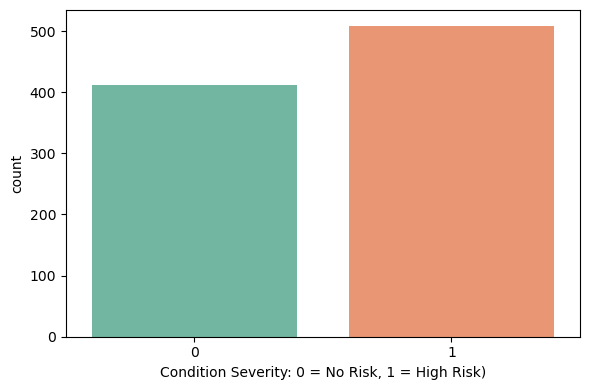

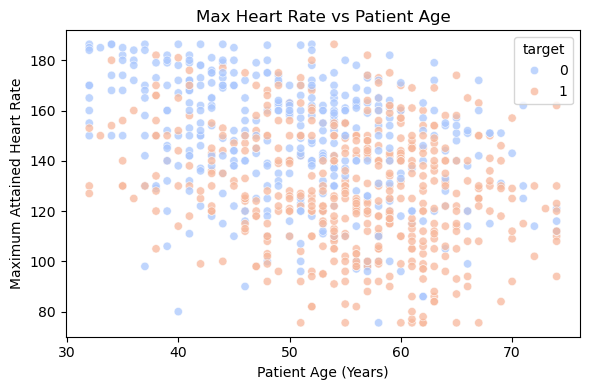

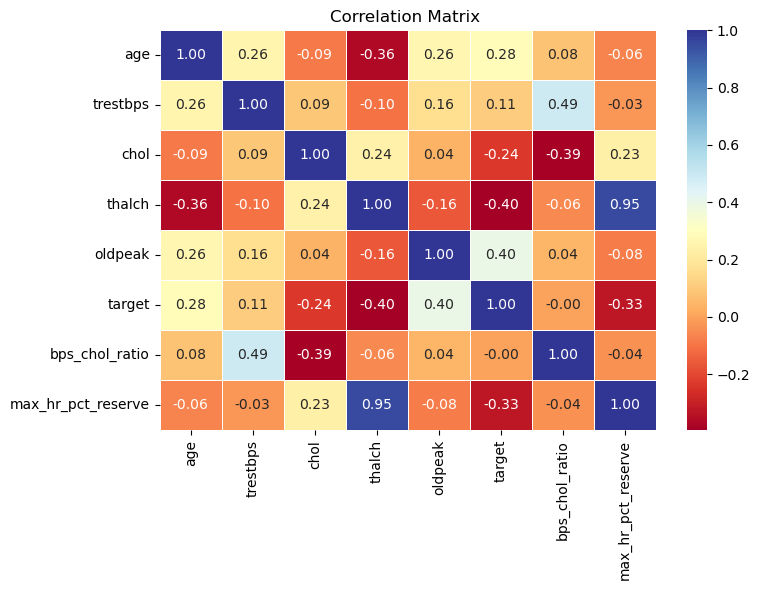

In [8]:
# Target Diagnostics Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='target', hue='target', palette='Set2', legend=False)
plt.xlabel('Condition Severity: 0 = No Risk, 1 = High Risk)')
plt.tight_layout()
plt.show()

# Scatter Profiling - Max Heart Rate vs Patient Age
plt.figure(figsize=(6, 4))
sns.scatterplot(data=train_df, x='age', y='thalch', hue='target', alpha=0.75, palette='coolwarm')
plt.title('Max Heart Rate vs Patient Age')
plt.xlabel('Patient Age (Years)')
plt.ylabel('Maximum Attained Heart Rate')
plt.tight_layout()
plt.show()

# Numerical Feature correlation heatmap
plt.figure(figsize=(8, 6))
numeric_only_df = train_df.select_dtypes(include=[np.number])
linear_correlations = numeric_only_df.corr()
sns.heatmap(linear_correlations, annot=True, fmt='.2f', cmap='RdYlBu', cbar=True, linewidths=0.4)
plt.title('Correlation Matrix ')
plt.tight_layout()
plt.show()

### Data Transformation

In [9]:
# Separate data and target
X = train_df.drop(columns=['target'])
y = train_df['target']

# Prepare list of neumerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'bool', 'category']).columns.tolist()

# Strign type conversion
for col in cat_cols:
    X[col] = X[col].astype(str)

# Numerical preprocessing with StandardScaler
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# categorical preprocessing with OneHotEncoder
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # imputr with mode
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
])

# features pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# 80-20 Train-Test Split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit preprocessing 
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


### Model Building and Evaluation

In [10]:
print("+++++++ Training and Evaluating Models +++++++++")

# create a model folder to store models
os.makedirs('model', exist_ok=True)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

results_list = []
for name, model in models.items():
    # Model Training
    model.fit(X_train_processed, y_train)
    
    # Run evaluation checks
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)[:, 1]
    
    # collect metrics - Accuracy, AUC, Precision, Recall, F1, MCC
    metrics = {
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_proba),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }
    results_list.append(metrics)
    
    # Save optimized model files in the model folder
    model_filename = f"model/{name.lower().replace(' ', '_')}.joblib"
    joblib.dump(model, model_filename)
    print(f"Saved model {name} to -> {model_filename}")

# Tabulate evaluation results into comparison configurations summaries
results_df = pd.DataFrame(results_list)
print("--- Comparing Model Results ---")
print(results_df.to_string(index=False))

+++++++ Training and Evaluating Models +++++++++
Saved model Logistic Regression to -> model/logistic_regression.joblib
Saved model Decision Tree to -> model/decision_tree.joblib
Saved model KNN to -> model/knn.joblib
Saved model Naive Bayes to -> model/naive_bayes.joblib
Saved model Support Vector Machine to -> model/support_vector_machine.joblib
--- Comparing Model Results ---
         ML Model Name  Accuracy      AUC  Precision   Recall       F1      MCC
   Logistic Regression  0.858696 0.927068   0.845455 0.911765 0.877358 0.714074
         Decision Tree  0.815217 0.858800   0.846939 0.813725 0.830000 0.628399
                   KNN  0.836957 0.902260   0.839623 0.872549 0.855769 0.669083
           Naive Bayes  0.842391 0.915531   0.847619 0.872549 0.859903 0.680239
Support Vector Machine  0.820652 0.911167   0.810811 0.882353 0.845070 0.636261


### Preparing artifacts for Steamlite app     

In [11]:
joblib.dump(preprocessor, 'model/preprocessor.joblib')
    
test_export_df = pd.DataFrame(X_test, columns=X.columns)
test_export_df['target'] = y_test.values
test_export_df.to_csv('test_data.csv', index=False)
# test_data.csv will be uploaded in the github

test_export_df

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,age_group,bps_chol_ratio,max_hr_pct_reserve,target
514,49,Male,Hungary,asymptomatic,130.0,206.0,False,normal,170.00,False,0.0,nan,nan,Middle-Aged,0.631068,0.994152,1
825,61,Male,VA Long Beach,asymptomatic,120.0,282.0,False,st-t abnormality,135.00,True,4.0,downsloping,fixed defect,Senior,0.425532,0.849057,1
854,55,Male,VA Long Beach,asymptomatic,172.0,260.0,False,normal,75.56,False,2.0,nan,nan,Middle-Aged,0.661538,0.457939,1
804,65,Male,VA Long Beach,asymptomatic,136.0,248.0,False,normal,140.00,True,4.0,downsloping,nan,Senior,0.548387,0.903226,1
887,69,Male,VA Long Beach,non-anginal,NaN,271.0,False,lv hypertrophy,NaN,nan,NaN,nan,nan,Senior,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,51,Male,Cleveland,typical angina,125.0,213.0,False,lv hypertrophy,125.00,True,1.4,upsloping,normal,Middle-Aged,0.586854,0.739645,0
815,63,Male,VA Long Beach,asymptomatic,160.0,267.0,True,st-t abnormality,88.00,True,2.0,nan,nan,Senior,0.599251,0.560510,1
631,51,Male,Switzerland,asymptomatic,140.0,0.0,False,normal,75.56,False,0.0,flat,normal,Middle-Aged,0.627803,0.447101,1
740,58,Male,VA Long Beach,asymptomatic,116.0,0.0,False,normal,124.00,False,1.0,upsloping,nan,Senior,0.520179,0.765432,1


In [13]:
# verion of libraries
library_manifest = {
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "joblib": joblib.__version__
}

print("=== Dependency for requirements.txt file ===")
for library_name, version_number in library_manifest.items():
    print(f"{library_name}=={version_number}")

=== Dependency for requirements.txt file ===
scikit-learn==1.7.2
numpy==2.3.5
pandas==2.3.3
matplotlib==3.10.6
seaborn==0.13.2
joblib==1.5.2
